# Risk Parity, Relaxed Risk Parity and Regimes: Equal Risk Contributions across Ten Asset-Class ETFs since 2007, Return-Seeking Relaxed Risk Parity with Kalman-Filtered Expected Returns, and Hidden-Markov Regime Covariances

A 60/40 portfolio looks balanced in dollars, but about 90% of its risk comes from equities: stocks are three to four times as volatile as Treasuries. **Risk parity** balances risk instead of capital. In the **equal-risk-contribution (ERC)** portfolio each asset contributes the same share of total volatility, so low-volatility assets such as Treasuries get large weights and equities small ones. The idea needs no expected-return forecasts, which are the least reliable input in portfolio construction, and it held up well through 2008, but it suffered in 2022 when stocks and bonds fell together.

Two extensions address its weak points:

- **Relaxed risk parity** (Gambeta and Kwon) keeps risk contributions close to equal but lets the optimiser tilt towards assets with higher expected returns, up to a chosen return target. It is a second-order cone program. Its expected returns here come from a **Kalman filter** that treats each asset's expected return as a slowly drifting hidden state.
- **Regime covariances**: correlations are not constant. A **hidden Markov model** on stocks, Treasuries and high-yield bonds identifies calm and stressed regimes, and the portfolio is built on the covariance expected for next month given the probability of each regime.

Everything is evaluated walk-forward on ten asset-class ETFs from 2008 to today, rebalanced monthly with transaction costs, against 1/N, 60/40 and the minimum-variance portfolio, and with risk parity levered to the volatility of 60/40.

**Data.** Yahoo Finance (daily prices of SPY, EFA, EEM, TLT, IEF, LQD, HYG, GLD, DBC and VNQ); FRED (3-month Treasury bill).

**Methods.** Equal risk contribution (Spinu's convex formulation), minimum variance, relaxed risk parity as a second-order cone program (cvxpy), Ledoit–Wolf shrinkage, local-level Kalman filter with maximum-likelihood noise variances, two-state Gaussian hidden Markov model (hmmlearn) with regime-weighted covariances, walk-forward backtest, Sharpe ratio, drawdown, expected shortfall, turnover, risk-contribution dispersion.

**Key output.** Weights and risk contributions of each portfolio over time; walk-forward performance including 2008, 2020 and 2022; whether Kalman-filtered returns or regime covariances add anything to plain risk parity.

## 1. The mathematics in brief

For weights *x* and covariance Σ, portfolio volatility σ(*x*) = √(*x*ᵀΣ*x*) splits exactly into **risk contributions** RCᵢ = *x*ᵢ(Σ*x*)ᵢ / σ(*x*), which sum to σ(*x*).

| Portfolio | Problem |
|---|---|
| 1/N | *x*ᵢ = 1/N |
| 60/40 | 60% S&P 500 (SPY), 40% intermediate Treasuries (IEF) |
| Minimum variance | minimise *x*ᵀΣ*x* subject to Σ*x*ᵢ = 1, *x* ≥ 0 |
| Equal risk contribution | RCᵢ equal for all *i*; found by minimising ½*y*ᵀΣ*y* − (1/N)Σ log *y*ᵢ and normalising *x* = *y* / Σ*y* |
| Relaxed risk parity | minimise ψ − γ subject to ζ = Σ*x*, *x*ᵢζᵢ ≥ γ²/N, ‖*L*ᵀ*x*‖ ≤ *q*, ‖(*q*, √N ρ)‖ ≤ √N ψ, λ *x*ᵀΘ*x* ≤ ρ², μᵀ*x* ≥ *R*, Σ*x*ᵢ = 1, *x* ≥ 0 |

In relaxed risk parity Θ is the diagonal of Σ and *L* its Cholesky factor. With no return target the solution is the ERC portfolio; the return target *R* forces a tilt, and λ controls how far risk contributions may drift from equality to reach it. Here *R* is the ERC portfolio's expected return plus 30% of the gap to the highest expected return among the assets, and λ = 1.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import cvxpy as cp
import yfinance as yf
from hmmlearn.hmm import GaussianHMM
from scipy import optimize, stats
from sklearn.covariance import LedoitWolf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
ASSETS = {
    "SPY": "US equities",
    "EFA": "Developed ex-US equities",
    "EEM": "Emerging equities",
    "TLT": "Long Treasuries",
    "IEF": "Intermediate Treasuries",
    "LQD": "Investment-grade credit",
    "HYG": "High-yield credit",
    "GLD": "Gold",
    "DBC": "Commodities",
    "VNQ": "US real estate",
}
# trading days of returns behind each covariance estimate
COV_WINDOW = 252
# one-way transaction cost per unit of turnover
COST_BPS = 5
# return target position and diagonal penalty in relaxed risk parity
RRP_KAPPA, RRP_LAMBDA = 0.30, 1.0
HMM_FEATURES = ["SPY", "TLT", "HYG"]
HMM_REFIT_MONTHS = 12

print(
    f"cvxpy {cp.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

cvxpy 1.9.3 · yfinance 1.7.0 · run on 2026-11-11


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

Total-return prices (dividends reinvested) of ten ETFs covering equities, government and corporate bonds, gold, commodities and real estate. The common history starts in April 2007, when the high-yield ETF began trading; with one year of returns needed for the first covariance, the backtest starts in May 2008, before the Lehman collapse.

In [3]:
def fetch_prices():
    px = yf.download(
        list(ASSETS),
        start="2007-01-01",
        auto_adjust=True,
        progress=False,
        threads=True,
    )["Close"]
    return px[list(ASSETS)]


PX = cached("etf_prices", fetch_prices, max_age_hours=24)
PX.index = pd.to_datetime(PX.index)
PX = PX.dropna()
RET = np.log(PX).diff().dropna()
RF = cached(
    "tbill",
    lambda: fred.get_series("DTB3").rename("rate").to_frame(),
    max_age_hours=24,
)["rate"]
RF.index = pd.to_datetime(RF.index)
RF_D = (RF / 100 / 252).reindex(RET.index).ffill().fillna(0)

summary = pd.DataFrame({
    "asset class": pd.Series(ASSETS),
    "start": PX.apply(lambda s: s.first_valid_index().date()),
    "annual return": RET.mean() * 252,
    "annual volatility": RET.std() * np.sqrt(252),
    "worst month": PX.resample("ME").last().pct_change().min(),
})
print(
    f"{len(RET):,} daily returns, {RET.index.min():%Y-%m-%d} →"
    f" {RET.index.max():%Y-%m-%d}"
)
summary.style.format({
    "annual return": "{:.1%}",
    "annual volatility": "{:.1%}",
    "worst month": "{:.1%}",
})

4,929 daily returns, 2007-04-12 → 2026-11-11


,asset class,start,annual return,annual volatility,worst month
SPY,US equities,2007-04-11,10.3%,19.6%,-16.5%
EFA,Developed ex-US equities,2007-04-11,4.5%,21.6%,-20.8%
EEM,Emerging equities,2007-04-11,4.3%,27.9%,-25.6%
TLT,Long Treasuries,2007-04-11,2.7%,15.1%,-13.1%
IEF,Intermediate Treasuries,2007-04-11,3.0%,6.9%,-4.7%
LQD,Investment-grade credit,2007-04-11,3.8%,8.8%,-10.7%
HYG,High-yield credit,2007-04-11,4.7%,10.8%,-11.5%
GLD,Gold,2007-04-11,8.7%,18.3%,-16.1%
DBC,Commodities,2007-04-11,2.1%,19.3%,-25.1%
VNQ,US real estate,2007-04-11,5.2%,29.5%,-31.7%


## 4. Portfolio construction

Each month-end the covariance is estimated from the last year of daily returns with **Ledoit–Wolf shrinkage**, which pulls the sample covariance towards a structured target and keeps it well conditioned. Minimum variance and ERC need only the covariance. The relaxed risk parity solver is written in cvxpy, with the hyperbolic constraints *x*ᵢζᵢ ≥ γ²/N expressed as rotated second-order cones.

In [4]:
def shrunk_cov(R):
    return LedoitWolf().fit(R).covariance_ * 252


def risk_contrib(x, S):
    m = S @ x
    return x * m / np.sqrt(x @ m)


def min_variance(S):
    n = len(S)
    x = cp.Variable(n)
    cp.Problem(
        cp.Minimize(cp.quad_form(x, cp.psd_wrap(S))), [cp.sum(x) == 1, x >= 0]
    ).solve()
    return np.clip(x.value, 0, None) / np.clip(x.value, 0, None).sum()


def erc(S, budget=None):
    n = len(S)
    b = np.full(n, 1 / n) if budget is None else budget
    f = lambda y: 0.5 * y @ S @ y - b @ np.log(y)
    g = lambda y: S @ y - b / y
    res = optimize.minimize(
        f,
        np.full(n, 1 / np.sqrt(np.diag(S)).sum()) / np.sqrt(np.diag(S)),
        jac=g,
        method="L-BFGS-B",
        bounds=[(1e-10, None)] * n,
        options={"maxiter": 5000, "gtol": 1e-12},
    )
    return res.x / res.x.sum()


def relaxed_risk_parity(S, mu, kappa=RRP_KAPPA, lam=RRP_LAMBDA):
    n = len(S)
    x_erc = erc(S)
    target = mu @ x_erc + kappa * max(mu.max() - mu @ x_erc, 0)
    L = np.linalg.cholesky(S + 1e-12 * np.eye(n))
    x, zeta = cp.Variable(n), cp.Variable(n)
    psi, gamma, rho, q = (
        cp.Variable(nonneg=True),
        cp.Variable(nonneg=True),
        cp.Variable(nonneg=True),
        cp.Variable(nonneg=True),
    )
    cons = [
        zeta == S @ x,
        cp.sum(x) == 1,
        x >= 0,
        mu @ x >= target,
        cp.norm(L.T @ x) <= q,
        cp.norm(cp.hstack([q, np.sqrt(n) * rho])) <= np.sqrt(n) * psi,
        cp.norm(cp.multiply(np.sqrt(lam * np.diag(S)), x)) <= rho,
    ]
    cons += [
        cp.quad_over_lin(gamma / np.sqrt(n), x[i]) <= zeta[i] for i in range(n)
    ]
    prob = cp.Problem(cp.Minimize(psi - gamma), cons)
    try:
        prob.solve(solver=cp.CLARABEL)
    except Exception:
        prob.solve()
    if x.value is None or prob.status not in ("optimal", "optimal_inaccurate"):
        return x_erc
    w = np.clip(x.value, 0, None)
    return w / w.sum()


S0 = shrunk_cov(RET.iloc[-COV_WINDOW:])
mu0 = RET.iloc[-756:].mean().to_numpy() * 252
demo = pd.DataFrame(
    {
        "min variance": min_variance(S0),
        "ERC": erc(S0),
        "relaxed RP (3-year mean)": relaxed_risk_parity(S0, mu0),
    },
    index=list(ASSETS),
)
rc = pd.DataFrame(
    {
        k: (
            risk_contrib(v.to_numpy(), S0)
            / np.sqrt(v.to_numpy() @ S0 @ v.to_numpy())
        )
        for k, v in demo.items()
    },
    index=list(ASSETS),
)
print("Latest weights and shares of risk:")
pd.concat({"weight": demo, "share of risk": rc}, axis=1).style.format("{:.1%}")

Latest weights and shares of risk:


## 5. Expected returns from a Kalman filter

Relaxed risk parity needs expected returns. A trailing mean is noisy and reacts slowly; treating the expected return as a hidden state gives a principled alternative. The **local-level model** for monthly returns is

*r*ₜ = μₜ + εₜ, εₜ ~ N(0, σ²ε) · μₜ = μₜ₋₁ + ηₜ, ηₜ ~ N(0, σ²η).

The Kalman filter updates the estimate of μₜ each month by a gain that depends on the signal-to-noise ratio σ²η / σ²ε. The two variances are estimated by maximum likelihood on the data available at each annual refit, and the filter is run forward with no look-ahead. A signal-to-noise ratio near zero means the filter is close to the long-run mean; a large one means it chases recent returns.

In [5]:
def kalman_local_level(y, q, r, m0=0.0, p0=1.0):
    m, p, out, ll = m0, p0, [], 0.0
    for obs in y:
        # predict
        p_pred = p + q
        s = p_pred + r
        ll += -0.5 * (np.log(2 * np.pi * s) + (obs - m) ** 2 / s)
        # update
        k = p_pred / s
        m = m + k * (obs - m)
        p = (1 - k) * p_pred
        out.append(m)
    return np.array(out), ll


def fit_local_level(y):
    v = np.var(y)
    nll = lambda th: -kalman_local_level(
        y, np.exp(th[0]), np.exp(th[1]), m0=np.mean(y[:12]), p0=v
    )[1]
    res = optimize.minimize(
        nll,
        x0=[np.log(v * 0.01), np.log(v)],
        method="Nelder-Mead",
        options={"maxiter": 2000},
    )
    return np.exp(res.x)


MRET = np.log(PX.resample("ME").last()).diff().dropna()
REBAL = MRET.index[MRET.index >= RET.index[COV_WINDOW]]
KAL, SNR = {}, {}
for tk in ASSETS:
    est, params = pd.Series(index=MRET.index, dtype=float), None
    for i, d in enumerate(REBAL):
        hist = MRET.loc[:d, tk].to_numpy()
        # refit once a year
        if params is None or d.month == REBAL[0].month:
            params = fit_local_level(hist)
            SNR[(tk, d.year)] = params[0] / params[1]
        est[d] = kalman_local_level(
            hist, *params, m0=np.mean(hist[:12]), p0=np.var(hist)
        )[0][-1]
    KAL[tk] = est.dropna() * 12
KAL = pd.DataFrame(KAL)
HIST3 = (MRET.rolling(36, min_periods=12).mean() * 12).reindex(KAL.index)
NEXT = MRET.shift(-1).reindex(KAL.index) * 12


def ic(pred):
    return pd.Series({
        d: stats.spearmanr(pred.loc[d], NEXT.loc[d])[0]
        for d in pred.index
        if NEXT.loc[d].notna().all()
    })


IC = pd.DataFrame({"Kalman": ic(KAL), "3-year mean": ic(HIST3)})
snr = pd.Series(SNR).unstack()
print(
    "Signal-to-noise ratio σ²η/σ²ε, median across assets and refits:"
    f" {snr.stack().median():.4f}"
)
print(
    "Rank correlation between predicted and next-month returns across the ten"
    " assets:"
)
IC.agg(["mean", "std", "count"]).T.assign(
    **{"t-stat": lambda d: d["mean"] / d["std"] * np.sqrt(d["count"])}
).round(3)

Signal-to-noise ratio σ²η/σ²ε, median across assets and refits: 0.0000
Rank correlation between predicted and next-month returns across the ten assets:


,mean,std,count,t-stat
Kalman,0.01,0.43,223.00,0.51
3-year mean,0.03,0.48,223.00,0.96


## 6. Regimes from a hidden Markov model

A two-state **Gaussian hidden Markov model** is fitted to daily returns of US equities, long Treasuries and high-yield bonds, refitted once a year on all data available. Each state has its own mean and covariance; the transition matrix says how persistent the states are. Given the probability of each state today, the probability of each state a month ahead follows from the transition matrix raised to the power 21. The ten-asset covariance of each state is the covariance of daily returns weighted by the model's state probabilities, and the covariance used for next month mixes the two with the forecast probabilities. The stressed state is the one with the higher equity volatility.

In [6]:
def weighted_cov(R, w):
    w = w / w.sum()
    m = w @ R
    Z = R - m
    return (Z * w[:, None]).T @ Z * 252


REGIME_P, REGIME_COV, hmm, last_fit = {}, {}, None, None
for d in REBAL:
    hist = RET.loc[:d]
    if hmm is None or (d - last_fit).days > 365 * HMM_REFIT_MONTHS / 12 - 5:
        X = hist[HMM_FEATURES].to_numpy() * 100
        best = None
        for s in range(4):
            m = GaussianHMM(
                n_components=2,
                covariance_type="full",
                n_iter=300,
                random_state=SEED + s,
            ).fit(X)
            sc = m.score(X)
            if best is None or sc > best[0]:
                best = (sc, m)
        hmm, last_fit = best[1], d
        stressed = int(np.argmax([hmm.covars_[k][0, 0] for k in range(2)]))
    post = hmm.predict_proba(hist[HMM_FEATURES].to_numpy() * 100)
    ahead = post[-1] @ np.linalg.matrix_power(hmm.transmat_, 21)
    R_ = hist.iloc[-756:].to_numpy()
    covs = [weighted_cov(R_, post[-len(R_) :, k] + 1e-9) for k in range(2)]
    REGIME_P[d] = {
        "stressed now": post[-1, stressed],
        "stressed next month": ahead[stressed],
    }
    REGIME_COV[d] = ahead[0] * covs[0] + ahead[1] * covs[1]
REGIME_P = pd.DataFrame(REGIME_P).T

post_all = hmm.predict_proba(RET[HMM_FEATURES].to_numpy() * 100)[:, stressed]
STRESS = pd.Series(post_all, index=RET.index)
vol_by = pd.DataFrame({
    k: RET[STRESS.round() == v].std() * np.sqrt(252)
    for k, v in [("calm", 0), ("stressed", 1)]
})
corr_by = {
    k: RET[STRESS.round() == v].corr()["SPY"]
    for k, v in [("calm", 0), ("stressed", 1)]
}
print(
    f"Latest model: share of days in the stressed state {STRESS.mean():.0%};"
    " expected duration calm"
    f" {1 / (1 - hmm.transmat_[1 - stressed, 1 - stressed]):.0f} days,"
    f" stressed {1 / (1 - hmm.transmat_[stressed, stressed]):.0f} days"
)
vol_by.add_prefix("volatility, ").join(
    pd.DataFrame(corr_by).add_prefix("correlation with SPY, ")
).style.format("{:.2f}")

Latest model: share of days in the stressed state 23%; expected duration calm 29 days, stressed 9 days


,"volatility, calm","volatility, stressed","correlation with SPY, calm","correlation with SPY, stressed"
Ticker,,,,
SPY,0.12,0.35,1.00,1.00
EFA,0.14,0.38,0.79,0.92
EEM,0.18,0.48,0.72,0.87
TLT,0.12,0.22,-0.24,-0.36
IEF,0.06,0.10,-0.24,-0.34
LQD,0.06,0.15,0.03,0.27
HYG,0.05,0.21,0.68,0.69
GLD,0.16,0.24,0.11,0.04
DBC,0.16,0.28,0.25,0.50


## 7. Walk-forward backtest

At each month-end the weights are computed from data up to that day and held for the next month (with daily drift); turnover pays 5 basis points per unit traded. Seven strategies are compared:

- **1/N**, **60/40** and **minimum variance**: the benchmarks;
- **ERC**: risk parity on the shrunk one-year covariance;
- **ERC, regime covariance**: risk parity on the HMM-mixed covariance;
- **Relaxed RP, Kalman**: relaxed risk parity with Kalman-filtered expected returns;
- **Relaxed RP, 3-year mean**: the same with trailing three-year mean returns;
- **ERC levered to 60/40 volatility**: ERC scaled each month so its expected volatility equals that of 60/40 (capped at 3×), financed at the Treasury-bill rate. This is the form in which risk parity is run by most funds.

In [7]:
def backtest(weight_fn, name, leverage_fn=None):
    w_prev = np.zeros(len(ASSETS))
    daily, weights, turnover, lev = [], {}, [], []
    for i, d in enumerate(REBAL[:-1]):
        S = shrunk_cov(RET.loc[:d].iloc[-COV_WINDOW:])
        w = weight_fn(d, S)
        L = leverage_fn(d, S, w) if leverage_fn else 1.0
        weights[d] = w
        nxt = RET.loc[(RET.index > d) & (RET.index <= REBAL[i + 1])]
        simple = np.expm1(nxt.to_numpy())
        tc = COST_BPS / 1e4 * np.abs(L * w - w_prev).sum()
        # weights drift within the month
        grow = np.cumprod(1 + simple, axis=0) * w
        val = grow.sum(axis=1)
        port = np.r_[val[0], val[1:] / val[:-1]] - 1
        r = L * port - (L - 1) * RF_D.reindex(nxt.index).to_numpy()
        r[0] -= tc
        daily.append(pd.Series(r, index=nxt.index))
        w_prev = L * grow[-1] / val[-1]
        turnover.append(tc / (COST_BPS / 1e4))
        lev.append(L)
    return {
        "returns": pd.concat(daily).rename(name),
        "weights": pd.DataFrame(weights, index=list(ASSETS)).T,
        "turnover": np.mean(turnover) * 12,
        "leverage": np.mean(lev),
    }


W6040 = np.array(
    [0.6 if t == "SPY" else 0.4 if t == "IEF" else 0.0 for t in ASSETS]
)
STRATS = {
    "1/N": lambda d, S: np.full(len(ASSETS), 1 / len(ASSETS)),
    "60/40": lambda d, S: W6040,
    "minimum variance": lambda d, S: min_variance(S),
    "ERC": lambda d, S: erc(S),
    "ERC, regime covariance": lambda d, S: erc(REGIME_COV[d]),
    "relaxed RP, Kalman": lambda d, S: relaxed_risk_parity(
        S, KAL.loc[d].to_numpy()
    ),
    "relaxed RP, 3-year mean": lambda d, S: relaxed_risk_parity(
        S, HIST3.loc[d].to_numpy()
    ),
}
t0 = time.time()
BT = {k: backtest(f, k) for k, f in STRATS.items()}
BT["ERC levered to 60/40 volatility"] = backtest(
    STRATS["ERC"],
    "ERC levered to 60/40 volatility",
    leverage_fn=lambda d, S, w: float(
        np.clip(np.sqrt(W6040 @ S @ W6040 / (w @ S @ w)), 1, 3)
    ),
)
print(
    f"{len(REBAL) - 1} monthly rebalances × {len(BT)} strategies ·"
    f" {time.time() - t0:.0f} s"
)


def metrics(r):
    ex = r - RF_D.reindex(r.index)
    nav = np.exp(np.log1p(r).cumsum())
    m = (1 + r).resample("ME").prod() - 1
    return {
        "annual return": (nav.iloc[-1]) ** (252 / len(r)) - 1,
        "volatility": r.std() * np.sqrt(252),
        "Sharpe": ex.mean() / ex.std() * np.sqrt(252),
        "max drawdown": (nav / nav.cummax() - 1).min(),
        "monthly ES 5%": m[m <= m.quantile(0.05)].mean(),
        "2008-09 → 2009-02": (1 + r.loc["2008-09":"2009-02"]).prod() - 1,
        "2020-02 → 2020-03": (1 + r.loc["2020-02":"2020-03"]).prod() - 1,
        "2022": (1 + r.loc["2022"]).prod() - 1,
    }


PERF = pd.DataFrame({
    k: (
        metrics(v["returns"]) | {
            "turnover / year": v["turnover"],
            "average leverage": v["leverage"],
        }
    )
    for k, v in BT.items()
}).T
fmt = {c: "{:.1%}" for c in PERF.columns} | {
    "Sharpe": "{:.2f}",
    "turnover / year": "{:.1f}",
    "average leverage": "{:.2f}",
}
PERF.style.format(fmt)

223 monthly rebalances × 8 strategies · 22 s


,annual return,volatility,Sharpe,max drawdown,monthly ES 5%,2008-09 → 2009-02,2020-02 → 2020-03,2022,turnover / year,average leverage
1/N,5.5%,11.0%,0.42,-34.8%,-6.6%,-26.8%,-10.8%,-13.9%,0.4,1.00
60/40,8.3%,11.1%,0.65,-31.9%,-6.0%,-25.1%,-9.4%,-16.7%,0.3,1.00
minimum variance,3.1%,5.7%,0.31,-17.5%,-4.2%,-8.4%,-3.8%,-13.4%,1.1,1.00
ERC,4.6%,7.4%,0.45,-20.0%,-5.2%,-12.3%,-7.4%,-14.3%,0.5,1.00
"ERC, regime covariance",4.9%,7.2%,0.51,-19.5%,-4.9%,-11.7%,-4.8%,-14.0%,0.4,1.00
"relaxed RP, Kalman",5.3%,8.8%,0.47,-24.7%,-6.0%,-15.1%,-7.7%,-17.4%,2.3,1.00
"relaxed RP, 3-year mean",5.6%,8.7%,0.51,-24.7%,-5.9%,-15.1%,-7.5%,-17.2%,1.9,1.00
ERC levered to 60/40 volatility,6.5%,12.1%,0.47,-35.0%,-8.8%,-23.2%,-12.3%,-21.4%,1.1,1.55


### Is the difference in Sharpe ratios significant?

Sharpe ratios over 17 years are estimated with error. The difference between each strategy and plain ERC is tested with a stationary block bootstrap of daily excess returns (blocks averaging 21 days, 2,000 resamples), which keeps volatility clustering and the correlation between the two strategies.

In [8]:
def block_bootstrap_sharpe_diff(a, b, n_boot=2000, block=21, seed=SEED):
    r = np.random.default_rng(seed)
    X = np.column_stack([a, b])
    n = len(X)
    diffs = np.empty(n_boot)
    for k in range(n_boot):
        idx, i = np.empty(n, int), 0
        while i < n:
            start, length = r.integers(n), r.geometric(1 / block)
            seg = (start + np.arange(length)) % n
            take = min(length, n - i)
            idx[i : i + take] = seg[:take]
            i += take
        s = X[idx]
        sh = s.mean(axis=0) / s.std(axis=0) * np.sqrt(252)
        diffs[k] = sh[0] - sh[1]
    return diffs


base = BT["ERC"]["returns"]
ex = lambda r: (r - RF_D.reindex(r.index)).to_numpy()
rows = []
for k, v in BT.items():
    if k == "ERC":
        continue
    a, b = ex(v["returns"]), ex(base.reindex(v["returns"].index))
    d = block_bootstrap_sharpe_diff(a, b)
    obs = a.mean() / a.std() * np.sqrt(252) - b.mean() / b.std() * np.sqrt(252)
    rows.append({
        "strategy": k,
        "Sharpe minus ERC": obs,
        "90% low": np.quantile(d, 0.05),
        "90% high": np.quantile(d, 0.95),
        "share of resamples above ERC": (d > 0).mean(),
    })
SIG = pd.DataFrame(rows).set_index("strategy")
SIG.style.format({
    "Sharpe minus ERC": "{:+.2f}",
    "90% low": "{:+.2f}",
    "90% high": "{:+.2f}",
    "share of resamples above ERC": "{:.0%}",
})

,Sharpe minus ERC,90% low,90% high,share of resamples above ERC
strategy,,,,
1/N,-0.03,-0.20,+0.14,40%
60/40,+0.20,-0.05,+0.46,90%
minimum variance,-0.13,-0.26,-0.00,5%
"ERC, regime covariance",+0.06,-0.01,+0.13,93%
"relaxed RP, Kalman",+0.02,-0.13,+0.17,60%
"relaxed RP, 3-year mean",+0.06,-0.09,+0.21,74%
ERC levered to 60/40 volatility,+0.02,-0.06,+0.10,67%


### Are the risk contributions really equal?

Ex ante, ERC equalises risk contributions by construction. What matters is whether they stay balanced over the following month, measured with the realised covariance of that month. The dispersion of realised shares of risk (their standard deviation across assets, where 0 is perfect parity) is compared for 1/N, 60/40, ERC and its regime version.

In [9]:
rows = {}
for k in [
    "1/N",
    "60/40",
    "ERC",
    "ERC, regime covariance",
    "relaxed RP, Kalman",
]:
    W = BT[k]["weights"]
    disp = []
    for i, d in enumerate(W.index):
        nxt = RET.loc[(RET.index > d) & (RET.index <= REBAL[i + 1])]
        if len(nxt) < 15:
            continue
        S_real = np.cov(nxt.to_numpy().T) * 252
        w = W.loc[d].to_numpy()
        share = risk_contrib(w, S_real) / np.sqrt(w @ S_real @ w)
        disp.append(
            np.std(share[w > 1e-6]) if k != "60/40" else np.std(share[w > 0])
        )
    rows[k] = pd.Series(disp)
DISP = pd.DataFrame({
    k: {
        "median dispersion of realised risk shares": v.median(),
        "90th percentile": v.quantile(0.9),
    }
    for k, v in rows.items()
}).T
DISP.style.format("{:.3f}")

,median dispersion of realised risk shares,90th percentile
1/N,0.076,0.118
60/40,0.499,0.649
ERC,0.054,0.107
"ERC, regime covariance",0.063,0.114
"relaxed RP, Kalman",0.144,0.233


## 8. Charts

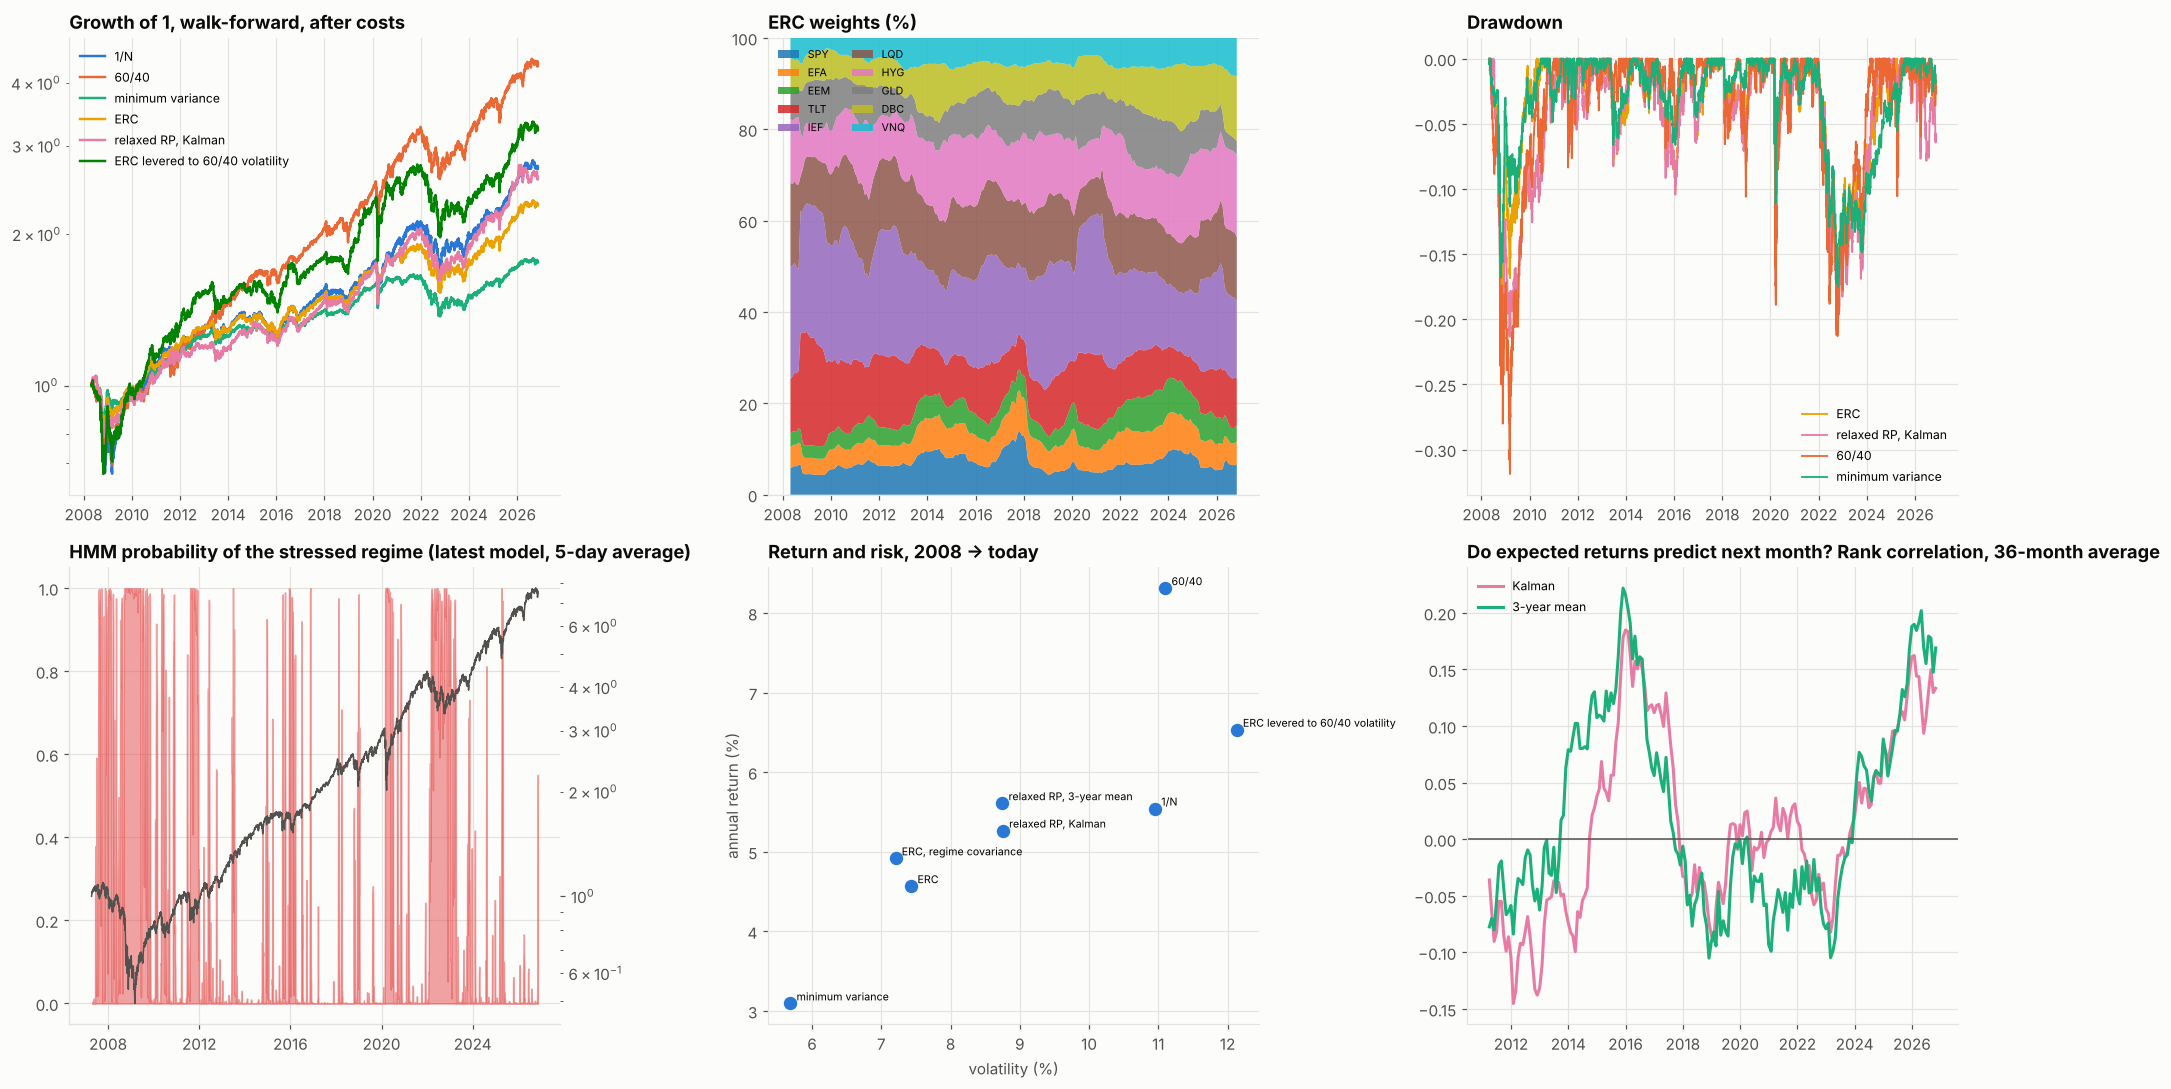

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
a = ax[0, 0]
show = [
    "1/N",
    "60/40",
    "minimum variance",
    "ERC",
    "relaxed RP, Kalman",
    "ERC levered to 60/40 volatility",
]
for i, k in enumerate(show):
    r = BT[k]["returns"]
    a.plot(np.exp(np.log1p(r).cumsum()), label=k, color=PALETTE[i], lw=1.6)
a.set_yscale("log")
a.set_title("Growth of 1, walk-forward, after costs")
a.legend(fontsize=8)

a = ax[0, 1]
W = BT["ERC"]["weights"]
a.stackplot(
    W.index,
    W.T.to_numpy() * 100,
    labels=list(ASSETS),
    colors=[plt.cm.tab10(i) for i in range(len(ASSETS))],
    alpha=0.85,
)
a.set_ylim(0, 100)
a.set_title("ERC weights (%)")
a.legend(fontsize=7, ncol=2, loc="upper left")

a = ax[0, 2]
for i, k in enumerate(
    ["ERC", "relaxed RP, Kalman", "60/40", "minimum variance"]
):
    r = BT[k]["returns"]
    nav = np.exp(np.log1p(r).cumsum())
    a.plot(
        nav / nav.cummax() - 1, label=k, color=PALETTE[[3, 4, 1, 2][i]], lw=1.2
    )
a.set_title("Drawdown")
a.legend(fontsize=8)

a = ax[1, 0]
a.fill_between(
    STRESS.index, STRESS.rolling(5).mean(), color=PALETTE[7], alpha=0.5
)
a.set_title(
    "HMM probability of the stressed regime (latest model, 5-day average)"
)
a2 = a.twinx()
a2.plot(PX.SPY / PX.SPY.iloc[0], color=INK_2, lw=1)
a2.set_yscale("log")
a2.grid(False)

a = ax[1, 1]
sel = [
    "1/N",
    "60/40",
    "minimum variance",
    "ERC",
    "ERC, regime covariance",
    "relaxed RP, Kalman",
    "relaxed RP, 3-year mean",
    "ERC levered to 60/40 volatility",
]
a.scatter(
    PERF.loc[sel, "volatility"] * 100,
    PERF.loc[sel, "annual return"] * 100,
    s=60,
    color=PALETTE[0],
)
for k in sel:
    a.annotate(
        k,
        (PERF.loc[k, "volatility"] * 100, PERF.loc[k, "annual return"] * 100),
        fontsize=7,
        xytext=(4, 2),
        textcoords="offset points",
    )
a.set_xlabel("volatility (%)")
a.set_ylabel("annual return (%)")
a.set_title("Return and risk, 2008 → today")

a = ax[1, 2]
roll = IC.rolling(36).mean()
a.plot(roll.index, roll["Kalman"], color=PALETTE[4], label="Kalman")
a.plot(roll.index, roll["3-year mean"], color=PALETTE[2], label="3-year mean")
a.axhline(0, color=INK_2, lw=1)
a.set_title(
    "Do expected returns predict next month? Rank correlation, 36-month"
    " average"
)
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_risk_parity_overview")
plt.show()

In [11]:
dash = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=(
        "Growth of 1",
        "ERC weights",
        "Probability of stressed regime",
    ),
)
for i, k in enumerate(show):
    r = BT[k]["returns"]
    dash.add_trace(
        go.Scatter(
            x=r.index,
            y=np.exp(np.log1p(r).cumsum()),
            name=k,
            line_color=PALETTE[i],
        ),
        1,
        1,
    )
for i, tk in enumerate(ASSETS):
    dash.add_trace(
        go.Scatter(
            x=W.index,
            y=W[tk] * 100,
            name=tk,
            stackgroup="w",
            line_color=(
                f"rgba{tuple(int(255 * c) for c in plt.cm.tab10(i)[:3]) + (1,)}"
            ),
        ),
        1,
        2,
    )
dash.add_trace(
    go.Scatter(
        x=STRESS.index,
        y=STRESS.rolling(5).mean(),
        name="stressed",
        line_color=PALETTE[7],
    ),
    1,
    3,
)
dash.update_yaxes(type="log", row=1, col=1)
dash.update_layout(
    height=600,
    width=1500,
    template="simple_white",
    title="Risk parity, relaxed risk parity and regimes",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

*Prices are re-read daily; every figure below comes from the run shown in this notebook (May 2008 to November 2026, 223 monthly rebalances, 5 basis points per unit of turnover).*

**Risk parity did what it promises on risk, not on return.**

| | Annual return | Volatility | Sharpe | Max drawdown | Sept 2008 – Feb 2009 | 2022 |
|---|---|---|---|---|---|---|
| 60/40 | 8.3% | 11.1% | 0.65 | −31.9% | −25.1% | −16.7% |
| 1/N | 5.5% | 11.0% | 0.42 | −34.8% | −26.8% | −13.9% |
| Minimum variance | 3.1% | 5.7% | 0.31 | −17.5% | −8.4% | −13.4% |
| ERC | 4.6% | 7.4% | 0.45 | −20.0% | −12.3% | −14.3% |
| ERC, regime covariance | 4.9% | 7.2% | 0.51 | −19.5% | −11.7% | −14.0% |
| Relaxed RP, Kalman | 5.3% | 8.8% | 0.47 | −24.7% | −15.1% | −17.4% |
| ERC levered to 60/40 volatility | 6.5% | 12.1% | 0.47 | −35.0% | −23.2% | −21.4% |

- **The weights.** ERC holds on average 22% intermediate Treasuries, 14% investment-grade credit, 13% high yield and 12% long Treasuries, but only 7% US equities. Each asset carries about a tenth of the risk ex ante.
- **Risk contributions stay balanced ex post.** Measured with the next month's realised covariance, the median dispersion of risk shares is 0.05 for ERC, against 0.08 for 1/N and 0.50 for 60/40, where equities carry almost all of the realised risk (Treasuries, negatively correlated with stocks, contribute close to nothing).
- **Crises.** ERC lost half as much as 60/40 from September 2008 to February 2009 (−12% against −25%).
- **The return problem.** This sample is the best period on record for US equities: SPY returned 10.3% a year, against 2–5% for most other assets. A portfolio that deliberately underweights equities trails 60/40 by about 4 points a year. Levering ERC 1.55× on average to the volatility of 60/40 (financed at the bill rate) lifts the return to 6.5%, still below 60/40, with a deeper drawdown. Leverage cannot rescue a portfolio whose diversifying assets earned little.
- **2022 is the known weak spot.** With stocks and bonds falling together, ERC lost 14% and the levered version 21%, more than 60/40 (−17%), because its largest positions were the bonds that fell most.
- **None of the differences is statistically decisive.** In a block bootstrap, the Sharpe gap between 60/40 and ERC (+0.20) has a 90% interval of −0.05 to +0.46. Only minimum variance is reliably worse than ERC (−0.13, interval −0.26 to 0.00).

**The Kalman filter learns that expected returns barely move.** The maximum-likelihood signal-to-noise ratio σ²η/σ²ε is essentially zero for every asset and every refit. The data cannot distinguish a drifting expected return from a constant one, so the filter collapses to the long-run average. Its forecasts have no power to rank next month's returns: the average rank correlation is 0.01 (t = 0.5), and 0.03 for the three-year mean (t = 1.0). Relaxed risk parity therefore tilts towards the assets that did best historically: US equities (20% on average), gold and long Treasuries. It gains about 0.7 points of return for 1.4 points of volatility and nearly five times the turnover of ERC. The risk balance it gives up (dispersion 0.14 against 0.05) is not repaid in Sharpe ratio (+0.02 over ERC, interval −0.13 to +0.17).

**Regimes help a little, for a simpler reason than expected.** The two-state HMM separates a calm regime (SPY volatility 12%, high yield 5%) from a stressed regime (35% and 21%) that covers 23% of days. In the stressed regime diversification among risky assets weakens: the correlation with US equities rises from 0.79 to 0.92 for developed markets, from 0.55 to 0.81 for real estate, from 0.25 to 0.50 for commodities and from 0.03 to 0.27 for investment-grade credit. Treasuries hedge better (long Treasuries −0.36 against −0.24), and real-estate and emerging-market volatility roughly triple. The stressed probability averaged 0.82 in 2008, 0.39 in 2020 and 0.70 in 2022. The expected stress spell lasts only nine days, however, so the forecast for a month ahead is close to the unconditional 23% except in long crises such as 2008. In practice the regime covariance is a three-year covariance that gives stress episodes their long-run weight. It improved the Sharpe ratio by 0.06 (93% of bootstrap resamples above ERC) and cut the February–March 2020 loss from −7.4% to −4.8%. A plain longer, stress-weighted window would probably capture most of this.

**Limitations.**
- **One sample, one regime for equities.** Seventeen years dominated by US equity outperformance and, until 2022, falling rates that favoured bonds. Risk parity's long-run case rests on longer histories than ETFs allow.
- **ETFs, not futures.** Professional risk parity holds futures and levers bonds cheaply. Here leverage is financed at the T-bill rate with no margin or roll costs, which flatters the levered version slightly. Transaction costs are a flat 5 basis points.
- **Covariance estimation.** One year of daily data with Ledoit–Wolf shrinkage. Other windows or exponential weighting change the weights, and every portfolio here depends on the covariance alone or almost alone.
- **Return target in relaxed risk parity.** The target (30% of the gap from the ERC return to the best expected return) and λ = 1 are fixed choices, not optimised. A different target moves the trade-off along the line between ERC and a return-chasing portfolio.
- **HMM specification.** Two states, three market series and an annual refit. More states, or regime models on the full set of assets, would separate rate-driven and credit-driven stress, as in 2022 versus 2008, but need more data than daily ETF history provides.

In [12]:
PERF.to_csv(OUT_DIR / "performance.csv")
SIG.to_csv(OUT_DIR / "sharpe_difference_bootstrap.csv")
DISP.to_csv(OUT_DIR / "risk_share_dispersion.csv")
IC.to_csv(OUT_DIR / "expected_return_rank_ic.csv")
REGIME_P.to_csv(OUT_DIR / "regime_probabilities.csv")
pd.concat({k: v["weights"] for k, v in BT.items()}, axis=1).to_csv(
    OUT_DIR / "weights.csv"
)
pd.concat([v["returns"] for v in BT.values()], axis=1).to_csv(
    OUT_DIR / "daily_returns.csv"
)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_risk_parity_overview.png, daily_returns.csv, dashboard.html, dashboard.png, expected_return_rank_ic.csv, performance.csv, regime_probabilities.csv, risk_share_dispersion.csv, sharpe_difference_bootstrap.csv, weights.csv


## References

- Maillard, S., Roncalli, T., & Teïletche, J. (2010). The properties of equally weighted risk contribution portfolios. *Journal of Portfolio Management*, 36(4), 60–70.
- Spinu, F. (2013). *An algorithm for computing risk parity weights*. SSRN 2297383.
- Gambeta, V., & Kwon, R. (2020). Risk return trade-off in relaxed risk parity portfolio optimization. *Journal of Risk and Financial Management*, 13(10), 237.
- Mausser, H., & Romanko, O. (2014). Computing equal risk contribution portfolios. *IBM Journal of Research and Development*, 58(4), 5:1–5:12.
- Asness, C. S., Frazzini, A., & Pedersen, L. H. (2012). Leverage aversion and risk parity. *Financial Analysts Journal*, 68(1), 47–59.
- Qian, E. (2005). *Risk parity portfolios: Efficient portfolios through true diversification*. PanAgora Asset Management.
- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal versus naive diversification: How inefficient is the 1/N portfolio strategy? *Review of Financial Studies*, 22(5), 1915–1953.
- Ledoit, O., & Wolf, M. (2004). A well-conditioned estimator for large-dimensional covariance matrices. *Journal of Multivariate Analysis*, 88(2), 365–411.
- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering*, 82(1), 35–45.
- Durbin, J., & Koopman, S. J. (2012). *Time Series Analysis by State Space Methods* (2nd ed.). Oxford University Press.
- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
- Ang, A., & Bekaert, G. (2002). International asset allocation with regime shifts. *Review of Financial Studies*, 15(4), 1137–1187.
- Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association*, 89(428), 1303–1313.
- Diamond, S., & Boyd, S. (2016). CVXPY: A Python-embedded modeling language for convex optimization. *Journal of Machine Learning Research*, 17(83), 1–5.